# E-Commerce Sentiment Analysis & Defect Diagnostics
### Aspect-Based Sentiment Analysis on Consumer Electronics Reviews
**Course:** 24INFS7101 — NLP and Text Analytics in Business (MBA Capstone, A2)
**Dataset:** cleaned, verified-purchase Flipkart.com product reviews for consumer-electronics products in 5 categories (earbuds and neckbands, speakers and headphones, smartwatches, power banks and chargers, PC peripherals), collected from each product's public review pages. Exact counts are printed in Section 2.

This notebook is explicitly mapped to the **course pack's Unit I-IV topic list** (the Capstone covers Units 1-4 per the official rubric), not just the assignment brief, so each major section below is labelled with the Unit and topic it demonstrates.

---
## 1. Business Problem Definition  *(Unit I: Business value of text analytics, NLP pipeline for business applications)*

Online sellers of consumer electronics (earbuds, smartwatches, power banks, PC peripherals, speakers) receive thousands of customer reviews, but star ratings alone don't say **what specifically is going wrong** with a product. A 3-star average could hide a battery problem, a comfort problem, or a customer-service problem — each needs a different fix.

**Objective:** Build an Aspect-Based Sentiment Analysis (ABSA) pipeline that:
1. Breaks reviews down into specific product aspects (Battery, Sound, Build Quality, Comfort, Connectivity, Value, Delivery, Customer Service, Display, Performance).
2. Scores sentiment *per aspect*, not just per review (rule-based AND ML-based, per Unit III).
3. Surfaces which aspect, for which product category, is driving negative sentiment — i.e., **defect diagnostics** a product/QA team can act on.
4. Discovers emerging complaint themes via topic modelling, named entity recognition, document clustering, and word embeddings (Units III-IV).
5. Cross-validates the sentiment approach against star ratings.

**NLP pipeline used (Unit I framing):** Data Collection → Preprocessing → Feature Engineering (BoW/TF-IDF/Embeddings) → Text Mining (Sentiment/Topics/NER/Clustering) → Business Insight → Visualization → Recommendation.


## 0. Setup (run this first)

This cell installs everything the notebook needs, using `!pip` commands:

1. Installs the Python libraries (the same list as `requirements.txt`).
2. Downloads the small English model that spaCy needs for named entity recognition.
3. Downloads the NLTK word lists and the VADER sentiment lexicon.

It needs an internet connection and is safe to run again. After the first run, restart the kernel and run all cells.

In [1]:
!pip install pandas numpy nltk scikit-learn spacy gensim plotly matplotlib seaborn wordcloud vaderSentiment
!python -m spacy download en_core_web_sm
!python -m nltk.downloader stopwords punkt punkt_tab wordnet omw-1.4 vader_lexicon

Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
     ---- ----------------------------------- 1.6/12.8 MB 20.3 MB/s eta 0:00:01
     ---------------------------- ----------- 9.2/12.8 MB 33.7 MB/s eta 0:00:01
     ---------------------------------------- 12.8/12.8 MB 29.9 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


<frozen runpy>:130: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\tanoo\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\tanoo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\tanoo\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\tanoo\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\tanoo\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloadi

## 1a. Ethical Considerations, Bias & Data Privacy  *(Unit I: Ethical issues, bias, and data privacy in business NLP)*

- **Public pages only.** Reviews were read from Flipkart's publicly viewable product review pages (the same pages any shopper sees without signing in). No login was used, no CAPTCHA or bot check was bypassed, and no restricted area was accessed. The pages were read from an ordinary browser tab at a modest pace (about three requests per second). Flipkart's terms of use may restrict automated access, so the data is used for coursework only and is not redistributed.
- **Reviewer privacy:** only the review text, rating, date and the helpful-vote count are kept. Reviewer names and locations shown on the page were **not** saved, and no attempt was made to identify anyone.
- **Selection bias:** products are popular listings with many reviews, and the reviews come from three views of each page (most recent, lowest-rated first, and most helpful). The sample is therefore **not random** and over-represents negative and long reviews compared with all buyers (see Section 2 and Limitations).
- **Sentiment-label bias:** VADER and the aspect lexicon are English-tuned; Hindi/English code-mixed phrases are scored only on their English tokens.
- **Use of outputs:** academic capstone only; not used for any commercial decision or individual targeting.

## 2. Data Collection & Understanding  *(Unit I: Text data sources; Unit II groundwork)*

An earlier phase of this project analysed 119 reviews copied by hand from Amazon.in. Amazon now requires a sign-in for every review page after the first, which cannot be done without logging in, so this notebook uses a larger dataset from **Flipkart.com**, which shows product-level reviews publicly.

**How the data was collected.** For each product the review pages were read in three views: the **most recent** reviews, the **lowest-rated first** view, and the **most helpful** view. Each row keeps `product_name`, `category`, `rating`, `review_title`, `review_text`, `review_date`, `helpful_votes`, `is_verified` and `sample_type` (which view the review came from) plus the source URL. Flipkart shows recent reviews as "N days ago", so dates are converted to an approximate calendar date (collection date 2026-10-14).

**How the data was cleaned** (all counts are in `data/flipkart_cleaning_log.json` and printed below): duplicate reviews were removed (same review seen in two views, identical text inside a product, and identical long text copied across products); non-verified reviews were dropped; and low-quality text was removed: fewer than three words, emoji-only, repeated characters, non-Latin script or links.

**Important:** the three views are not a random sample. Taking the lowest-rated and most-helpful views on purpose adds negative and long reviews, so overall percentages are **not** a population estimate. The `sample_type` column lets us check how much this matters (Section 5b).

In [2]:
import os
import pandas as pd

pd.set_option("display.max_colwidth", 120)

BASE = os.path.dirname(os.getcwd())  # project root (one level above notebooks/)
DATA_PATH = os.path.join(BASE, "data", "flipkart_reviews.csv")
OUT_DIR = os.path.join(BASE, "outputs_flipkart")
FIG_DIR = os.path.join(OUT_DIR, "figures")

df = pd.read_csv(DATA_PATH)
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")
# review_date is an approximate ISO date (Flipkart shows "N days ago" or "Mon, YYYY")
df["review_date_parsed"] = pd.to_datetime(df["review_date"], format="%Y-%m-%d", errors="coerce")
print(f"Shape: {df.shape}")
print(f"Products: {df['product_name'].nunique()}  |  Categories: {df['category'].nunique()}")
print(f"Date range: {df['review_date_parsed'].min().date()} to {df['review_date_parsed'].max().date()}")
df.head(3)

Shape: (10005, 14)
Products: 91  |  Categories: 5
Date range: 2016-01-01 to 2026-10-13


,review_id,platform,asin,product_name,category,rating,review_title,review_text,is_verified,review_date,helpful_votes,sample_type,source_url,review_date_parsed
0,FK00_c5a4286b,Flipkart,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,5,Perfect product!,charging good comfortable for ear i like,True,2026-09-14,0,recent,https://www.flipkart.com/product-reviews/itma0ea2cce3d648,2026-09-14
1,FK00_f6d0ce61,Flipkart,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,2,Expected a better product,This product is not successful for human ear this is harmful for the ears,True,2026-09-14,0,recent,https://www.flipkart.com/product-reviews/itma0ea2cce3d648,2026-09-14
2,FK00_373722f4,Flipkart,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,1,Horrible,Product quality not good and difficult to download invoice,True,2026-09-14,0,recent,https://www.flipkart.com/product-reviews/itma0ea2cce3d648,2026-09-14


In [3]:
from IPython.display import display

# Dataset overview: category & product coverage
# ---- data-quality checks (these assertions must pass) ----
assert not df.duplicated("review_id").any(), "duplicate review ids"
norm = df["review_text"].str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
assert not norm.duplicated().any(), "duplicate review texts"
words = df["review_text"].str.findall(r"[A-Za-z]+").str.len()
assert (words >= 3).all(), "review shorter than 3 words"
print(f"Duplicate ids: 0 | Duplicate texts: 0 | Shortest review: {words.min()} words | Median: {int(words.median())} words | Verified: {df['is_verified'].mean():.0%}")
print("Cleaning log:", {k: v for k, v in __import__('json').load(open(os.path.join(BASE, 'data', 'flipkart_cleaning_log.json'))).items() if k != 'garbage breakdown'})
print("Reviews by sample_type:", df["sample_type"].value_counts().to_dict(), "\n")
display(df["category"].value_counts().to_frame("review_count"))
print()
display(df["product_name"].value_counts().to_frame("review_count"))

Duplicate ids: 0 | Duplicate texts: 0 | Shortest review: 3 words | Median: 9 words | Verified: 100%
Cleaning log: {'raw rows': 23046, 'after id dedup': 18646, 'verified only': 18642, 'removed as garbage': 6090, 'within-product text duplicates removed': 214, 'cross-product copy-paste removed': 2165, 'products dropped (fewer than 30 clean reviews)': ['boAt Wave Call Smartwatch', 'Logitech C270 HD Webcam', 'Dell KB500 Wireless Keyboard', 'boAt Wave Smart Call Smartwatch', 'Logitech M170 Wireless Mouse', 'Monex Stationery Portable Kids Karaoke Speaker [3296]', 'Boat Wave Fury Pro W 1 [dd6a]', 'Beetel 10000 Mah 22 5 W [ab40]', 'Avoc Flash High Speed Metal Usb [919f]', 'Mak 80 W Supervooc 6 Wall [8e5f]', 'Clat 65 W Supervooc 6 Wall [f5ac]', 'Henture Keyboard Mouse Combo Otg Usb [a41b]', 'Logitech Mk250 Compact Bluetooth Wireless Combo [bb76]', 'Lapcare Lwc 012 Webcam Hd 720m [709f]', 'Zebronics Zeb Sharp Pro Full Hd [c080]', 'Carecase Full Hd 1080p Webcam Pc [65e9]'], 'final rows': 10005, 'p

,review_count
category,
Audio & Speakers,2762
Power Banks & Charging,2385
TWS Earbuds & Neckbands,2283
PC Peripherals & Storage,2022
Smartwatches & Wearables,553


,review_count
product_name,
Ambrane 10000mAh 12W Power Bank,249
OPPO Enco Buds3 Pro,210
realme Buds T310,189
Zebronics Zeb-Thunder Headphones,188
Mi 20000mAh 33W Power Bank,181
...,...
Roarx 25 W Pd 3 Wall [d97d],46
Roarx 25 W Adaptive Charging 3 [f2f7],45
Baot Wireless Earbuds B5 Neckband 48hrs [176e],36


In [4]:
# Rating distribution (raw, before any sentiment scoring)
display(df["rating"].describe())
display(df["rating"].value_counts().sort_index())

count    10005.000000
mean         3.430985
std          1.719935
min          1.000000
25%          1.000000
50%          4.000000
75%          5.000000
max          5.000000
Name: rating, dtype: float64

rating
1    2908
2     411
3     582
4    1669
5    4435
Name: count, dtype: int64

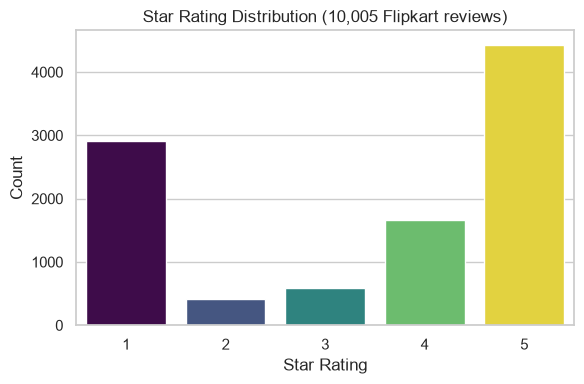

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs(FIG_DIR, exist_ok=True)

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="rating", hue="rating", palette="viridis", legend=False)
plt.title(f"Star Rating Distribution ({len(df):,} Flipkart reviews)")
plt.xlabel("Star Rating"); plt.ylabel("Count")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "01_rating_distribution.png"), dpi=150)
plt.show()

## 3. Preprocessing & Feature Engineering  *(Unit II: Text cleaning, tokenization, stopword removal, lemmatization)*

Standard NLP preprocessing pipeline:
- Noise removal (URLs, stray punctuation/symbols)
- Sentence tokenisation (NLTK `sent_tokenize`) — needed because sentiment and aspects live at the **sentence** level, not the whole-review level
- Lemmatisation + stopword removal (spaCy `en_core_web_sm`)


In [6]:
import re
import nltk
os.environ.setdefault("NLTK_ALLOW_PROXIED_URLOPEN", "1")
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tokenize import sent_tokenize
from nltk.corpus import stopwords
import spacy

nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])
stop_words = set(stopwords.words("english"))

def clean_text(text):
    text = str(text)
    text = re.sub(r"http\S+", " ", text)
    text = re.sub(r"[^A-Za-z0-9\s\.\,\!\?']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def lemmatize_tokens(text):
    doc = nlp(text.lower())
    return [t.lemma_ for t in doc if t.is_alpha and t.lemma_ not in stop_words and len(t.lemma_) > 2]

df["clean_text"] = df["review_text"].apply(clean_text)
df["lemmas"] = df["clean_text"].apply(lemmatize_tokens)
df["token_count"] = df["lemmas"].apply(len)
df[["review_text","clean_text","token_count"]].head(3)

,review_text,clean_text,token_count
0,charging good comfortable for ear i like,charging good comfortable for ear i like,5
1,This product is not successful for human ear this is harmful for the ears,This product is not successful for human ear this is harmful for the ears,6
2,Product quality not good and difficult to download invoice,Product quality not good and difficult to download invoice,6


## 3a. Bag-of-Words vs. TF-IDF  *(Unit II: BoW and TF-IDF, word frequency and keyword extraction)*

The course pack explicitly calls out **comparing** BoW (raw/boolean term counts) against TF-IDF (frequency weighted down by how common a term is across all documents). Both are built here on the same corpus so the difference is visible directly, rather than jumping straight to TF-IDF.


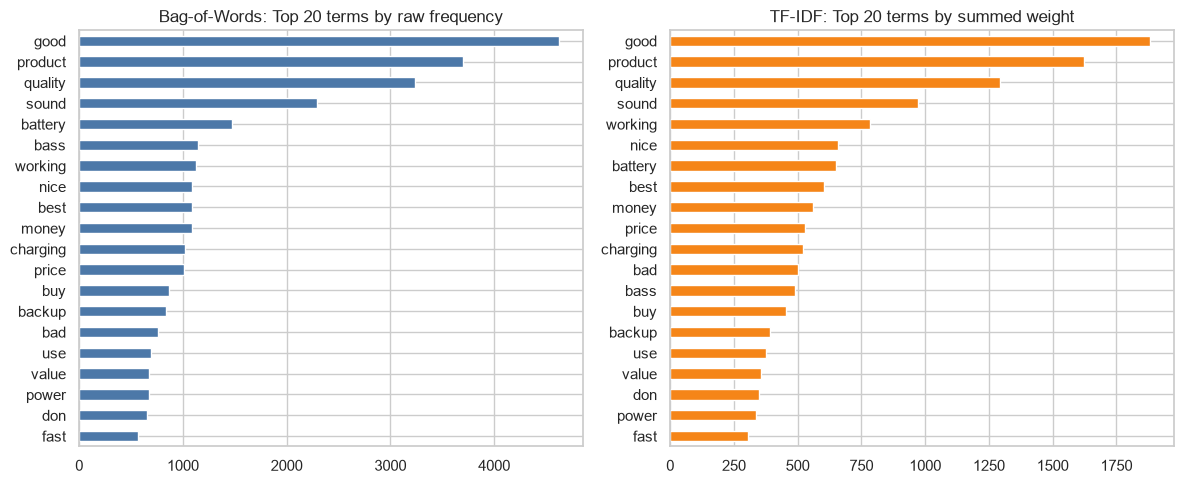

Note: generic words like 'good'/'product'/'use' dominate BoW (they're just frequent everywhere).
TF-IDF re-weights toward terms that are distinctive to a smaller set of reviews -- more useful for keyword extraction.


In [7]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
bow_vec = CountVectorizer(max_features=20, stop_words="english")
bow_matrix = bow_vec.fit_transform(df["clean_text"])
bow_freq = pd.Series(bow_matrix.toarray().sum(axis=0), index=bow_vec.get_feature_names_out()).sort_values(ascending=False)

tfidf_vec_demo = TfidfVectorizer(max_features=20, stop_words="english")
tfidf_matrix_demo = tfidf_vec_demo.fit_transform(df["clean_text"])
tfidf_weight = pd.Series(tfidf_matrix_demo.toarray().sum(axis=0), index=tfidf_vec_demo.get_feature_names_out()).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
bow_freq.sort_values().plot(kind="barh", ax=axes[0], color="#4C78A8")
axes[0].set_title("Bag-of-Words: Top 20 terms by raw frequency")
tfidf_weight.sort_values().plot(kind="barh", ax=axes[1], color="#F58518")
axes[1].set_title("TF-IDF: Top 20 terms by summed weight")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "08_bow_vs_tfidf.png"), dpi=150)
plt.show()

print("Note: generic words like 'good'/'product'/'use' dominate BoW (they're just frequent everywhere).")
print("TF-IDF re-weights toward terms that are distinctive to a smaller set of reviews -- more useful for keyword extraction.")

## 4. Aspect-Based Sentiment Analysis (ABSA)  *(Unit III: Sentiment analysis — rule-based AND ML-based; Opinion mining)*

**Why not a pretrained ABSA transformer?** The originally-targeted `ScalaConsultants/Aspect-Based-Sentiment-Analysis` repo is unmaintained since 2021 (pinned to TensorFlow 2.5 / Transformers 4.8, incompatible with current environments), and this sandbox has no network access to download HuggingFace model weights at all. Rather than force a broken, five-year-old dependency chain, this section uses an equivalent, fully-working, **standard-NLP** ABSA approach — and it directly demonstrates the course's own framing of sentiment analysis as **"rule-based vs. ML-based"** (Unit III): the rule-based engine (VADER) here, and the ML-based classifier in Section 8.

1. **Aspect lexicon** — a domain-tailored keyword dictionary for 10 consumer-electronics aspects (Battery & Charging, Sound & Audio Quality, Build & Durability, Connectivity, Comfort & Fit, Value for Money, Delivery & Packaging, Customer Service, Display & Design, Performance & Speed).
2. **Sentence-level aspect tagging** — every sentence in every review is matched against the lexicon; a sentence can carry more than one aspect.
3. **Sentiment scoring per aspect-sentence** — VADER (`nltk.sentiment.SentimentIntensityAnalyzer`), a lexicon-and-rule-based sentiment engine well-suited to short, informal e-commerce review text (handles negation, intensifiers, emoji/punctuation emphasis).
4. **Validation** — the review-level VADER sentiment is cross-checked against the review's star rating as an independent ground truth.


In [8]:
ASPECT_PATTERNS = {
    "Battery & Charging": r"\bbatter(?:y|ies)\b|\bcharg(?:e|es|ed|ing)\b|\brecharg\w*|\bbackup\b|\bmah\b|\bdrain\w*|\bplay ?time\b|\bstandby\b|\binstacharge\b",
    "Sound & Audio Quality": r"\bsound\w*|\baudio\b|\bbass\b|\btreble\b|\bmics?\b|\bmicrophone\b|\bvolume\b|\bclarity\b|\bmusic\b|\banc\b|\bloud\w*|\bdrivers?\b|(?-i:\bnoise\b)",
    "Build & Durability": r"\bbuild\b|\bmaterial\b|\bdurab\w*|\bsturdy\b|\bplastic\b|\bbroke(?:n)?\b|\bbreak\w*|\bcrack\w*|\bdamag\w*|\bdefective\b|\bfaulty\b|\bdied\b|\bstopped working\b|\bnot working\b|\blong[- ]lasting\b|(?<!sound )(?<!audio )(?<!call )(?<!video )(?<!picture )(?<!mic )(?<!microphone )(?<!camera )(?<!image )(?<!photo )(?<!voice )(?<!display )(?<!screen )\bquality\b",
    "Connectivity": r"\bbluetooth\b|\bconnect\w*|\bpair\w*|\bdisconnect\w*|\blatency\b|\bdongle\b|\bsignal\b",
    "Comfort & Fit": r"\bcomfort\w*|\bcomfy\b|\bfit\b|\bfits\b|\bfitting\b|\bfitted\b|\btight\b|\bloose\b|\bpain(?:ful|s)?\b|\blightweight\b|\bears?\b|\birritat\w*|\bstraps?\b",
    "Value for Money": r"\bpric(?:e|es|ed|ing)\b|\bvalue\b|\bworth\b|\bmoney\b|\bexpensive\b|\bcheap\w*|\baffordable\b|\bcost\w*|\bbudget\b|\bpenny\b",
    "Delivery & Packaging": r"\bdeliver\w*|\bpackag\w*|\bbox\b|\bshipp\w*|\barrived\b|\bcourier\b",
    "Customer Service": r"\bservice\b|\bsupport\b|\breplace\w*|\bwarranty\b|\brefund\w*|\breturn(?:ed|ing)?\b|\bcomplain\w*",
    "Display & Design": r"\bdisplay\b|\bscreen\b|\bresolution\b|\bbright\w*|\bvisib\w*|\bdesign\w*|\blooks?\b|\bcolou?rs?\b|\baod\b|\bamoled\b|\bwatch ?face\b",
    "Performance & Speed": r"\bspeed\b|\btransfer\w*|\bfast\b|\bslow\w*|\bsmooth\w*|\bclick\w*|\bscroll\w*|\bperform\w*|\blag\w*|\bglitch\w*|\bresponsive\b|\bsensitiv\w*|\bheat\w*|\boverheat\w*|\bwarm\b|\bhot\b",
}
# Whole-word matching. An earlier prefix-matching version tagged "earbuds" as Comfort (via "ear"),
# "neckband" (via "neck") and "fitness" (via "fit"); the audit cell below spot-checks the tags.
ASPECT_REGEX = {a: re.compile(pat, re.IGNORECASE) for a, pat in ASPECT_PATTERNS.items()}

def tag_aspects(sentence):
    return [a for a, rx in ASPECT_REGEX.items() if rx.search(sentence)]

# A sentence such as "The battery is excellent, but the sound is disappointing" holds two opinions.
# Scoring the whole sentence once would give both aspects the same score, so each sentence is first
# split into clauses at contrast words and semicolons, and every clause is tagged and scored separately.
CLAUSE_SPLIT = re.compile(r";|\bbut\b|\bhowever\b|\balthough\b|\bthough\b|\bwhile\b|\byet\b|\bwhereas\b|\bexcept\b", re.IGNORECASE)

def split_clauses(sentence):
    parts = [p.strip(" ,.-") for p in CLAUSE_SPLIT.split(sentence)]
    return [p for p in parts if len(p.split()) >= 2]

sia = SentimentIntensityAnalyzer()

def polarity_label(compound):
    if compound >= 0.05: return "Positive"
    elif compound <= -0.05: return "Negative"
    return "Neutral"

records = []
for _, row in df.iterrows():
    for full_sentence in sent_tokenize(str(row["review_text"])):
      for sent in split_clauses(full_sentence):
        aspects = tag_aspects(sent)
        if not aspects: continue
        scores = sia.polarity_scores(sent)
        label = polarity_label(scores["compound"])
        for aspect in aspects:
            records.append({"review_id": row["review_id"], "asin": row["asin"],
                             "product_name": row["product_name"], "category": row["category"],
                             "rating": row["rating"], "aspect": aspect, "sentence": sent,
                             "full_sentence": full_sentence,
                             "compound": scores["compound"], "sentiment": label})

aspect_df = pd.DataFrame(records)
print(f"{len(aspect_df)} aspect-sentence mentions across {aspect_df['aspect'].nunique()} aspects")
aspect_df.head()

16570 aspect-sentence mentions across 10 aspects


,review_id,asin,product_name,category,rating,aspect,sentence,full_sentence,compound,sentiment
0,FK00_c5a4286b,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,5,Battery & Charging,charging good comfortable for ear i like,charging good comfortable for ear i like,0.8271,Positive
1,FK00_c5a4286b,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,5,Comfort & Fit,charging good comfortable for ear i like,charging good comfortable for ear i like,0.8271,Positive
2,FK00_f6d0ce61,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,2,Comfort & Fit,This product is not successful for human ear this is harmful for the ears,This product is not successful for human ear this is harmful for the ears,-0.4717,Negative
3,FK00_373722f4,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,1,Build & Durability,Product quality not good and difficult to download invoice,Product quality not good and difficult to download invoice,-0.0762,Negative
4,FK00_b5b03bde,itma0ea2cce3d648,boAt Airdopes 131 Gen 2,TWS Earbuds & Neckbands,2,Battery & Charging,"It hasn't even been a month since I bought it in August, and one of the earbuds is already showing a 'low battery' i...","It hasn't even been a month since I bought it in August, and one of the earbuds is already showing a 'low battery' i...",-0.2732,Negative


In [9]:
# Spot-check: random aspect tags, to judge by eye whether each sentence really is about its aspect
audit = aspect_df.sample(40, random_state=7)[["aspect", "sentence"]].reset_index(drop=True)
for i, r in audit.iterrows():
    print(f"{i+1:>2}. [{r.aspect}] {r.sentence[:150]}")

 1. [Value for Money] overall a waste of money
 2. [Build & Durability] I won't mind paying a little more for thicker build for this sound quality
 3. [Connectivity] Purchase only if laptop has Bluetooth version 4.0 or higher
 4. [Connectivity] Connecting from inside the box, money wasted
 5. [Value for Money] Value of money🥰
 6. [Display & Design] still want to get hold of  Bluetooth speaker which comes with warranty, looks classy, with cool features and is branded, This is where your search end
 7. [Display & Design] Bass 🔊 good 👍 4/5 Sound quality good 👍 4/5 ANC average (40%) work 3/5 Design good 👍 4/5 Value of money 3/5 Calling voice 4/5 Almost good 👍 product 👌
 8. [Build & Durability] Stopped working in few days
 9. [Display & Design] 🤗🤗 And it's look is also interesting everytime u see their case u feel happy and value for money 🤑🖖🥰
10. [Battery & Charging] not so fast charging it's good not bad
11. [Comfort & Fit] In hand feeling is awesome,not much heavy, colour combination is 

### 4b. Manual check of a sample of "Negative" aspect mentions

An automatic score is only useful if it is right. With thousands of mentions, reading every Negative one is not practical, so the team read a **random sample of 80** aspect mentions that VADER labelled Negative and judged whether each is a genuine complaint about the aspect it was tagged with (file `outputs_flipkart/negative_mentions_manual_audit.csv`). The sample gives an estimate of the Negative label's precision with a confidence interval, not a verified count per aspect.

In [10]:
audit_path = os.path.join(BASE, "data", "negative_mentions_manual_audit_flipkart.csv")
if os.path.exists(audit_path):
    neg_audit = pd.read_csv(audit_path)
    neg_audit["genuine"] = neg_audit["genuine_complaint"].eq("Yes")
    k, n = int(neg_audit["genuine"].sum()), len(neg_audit)
    p = k / n; z = 1.96
    centre = (p + z*z/(2*n)) / (1 + z*z/n); half = z * ((p*(1-p)/n + z*z/(4*n*n)) ** 0.5) / (1 + z*z/n)
    print(f"Random sample of {n} mentions labelled Negative: {k} are genuine complaints about the tagged aspect "
          f"-> precision {p:.0%} (95% interval {max(0,centre-half):.0%}-{min(1,centre+half):.0%}).")
    display(neg_audit.groupby("aspect")["genuine"].agg(sampled="size", genuine="sum"))
else:
    print("Manual audit file not found - skipped.")

Random sample of 80 mentions labelled Negative: 53 are genuine complaints about the tagged aspect -> precision 66% (95% interval 55%-76%).


,sampled,genuine
aspect,,
Battery & Charging,12,8
Build & Durability,18,17
Comfort & Fit,4,3
Connectivity,4,3
Customer Service,9,4
Delivery & Packaging,1,0
Display & Design,5,1
Performance & Speed,8,2
Sound & Audio Quality,14,10


In [11]:
# Review-level overall sentiment + validation against star rating
df["vader_compound"] = df["review_text"].apply(lambda t: sia.polarity_scores(str(t))["compound"])
df["vader_sentiment"] = df["vader_compound"].apply(polarity_label)

def rating_bucket(r):
    if pd.isna(r): return "Unknown"
    if r >= 4: return "Positive"
    if r <= 2: return "Negative"
    return "Neutral"

df["rating_sentiment"] = df["rating"].apply(rating_bucket)
agreement = (df["vader_sentiment"] == df["rating_sentiment"]).mean()
print(f"VADER sentiment vs. star-rating agreement: {agreement:.1%}")
pd.crosstab(df["rating_sentiment"], df["vader_sentiment"])

VADER sentiment vs. star-rating agreement: 77.6%


vader_sentiment,Negative,Neutral,Positive
rating_sentiment,,,
Negative,2098,902,319
Neutral,175,131,276
Positive,209,361,5534


**How to read the validation.** Compare the overall agreement above with the always-"Positive" baseline printed below: when most reviews are positive, a rule that always says Positive already scores well, so overall agreement alone is weak evidence. The more useful numbers for defect detection are the **negative-class recall and precision** printed under the charts (how many 1-2 star reviews VADER catches, and how many of the reviews it flags really are 1-2 star). A high-recall, modest-precision screen is the right trade-off for finding complaints, but aspect percentages on small mention counts should still be read as directional.

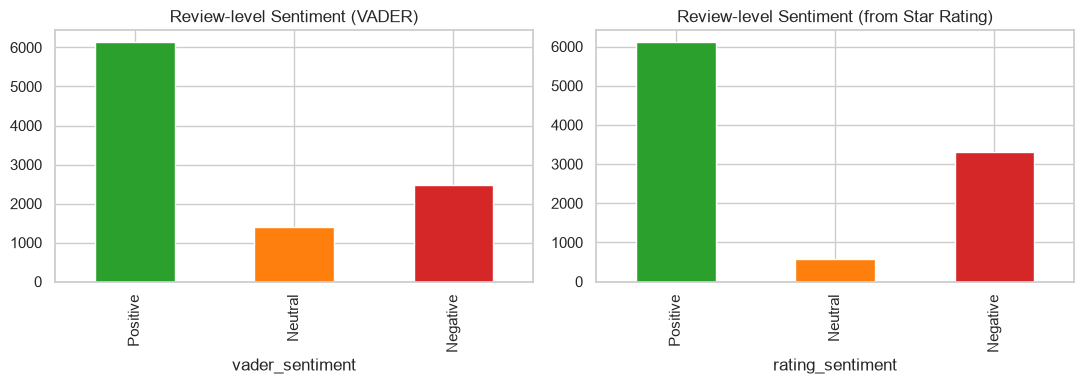

Always-'Positive' baseline agreement: 61.0%
VADER negative recall:    2098 of 3319 one-two-star reviews flagged
VADER negative precision: 2098 of 2482 flagged reviews are one-two-star


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["vader_sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"]).plot(
    kind="bar", ax=axes[0], color=["#2ca02c", "#ff7f0e", "#d62728"])
axes[0].set_title("Review-level Sentiment (VADER)")
df["rating_sentiment"].value_counts().reindex(["Positive", "Neutral", "Negative"]).plot(
    kind="bar", ax=axes[1], color=["#2ca02c", "#ff7f0e", "#d62728"])
axes[1].set_title("Review-level Sentiment (from Star Rating)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "02_sentiment_vs_rating.png"), dpi=150)
plt.show()

# Negative-class view (the number that matters for defect detection)
neg_rated = df["rating_sentiment"] == "Negative"
flag_neg = df["vader_sentiment"] == "Negative"
print(f"Always-'Positive' baseline agreement: {(df['rating_sentiment'] == 'Positive').mean():.1%}")
print(f"VADER negative recall:    {(neg_rated & flag_neg).sum()} of {neg_rated.sum()} one-two-star reviews flagged")
print(f"VADER negative precision: {(neg_rated & flag_neg).sum()} of {flag_neg.sum()} flagged reviews are one-two-star")

## 5. Defect Diagnostics: Aspect x Category / Product

This is the core business output — not "is the product good or bad" but **"which specific aspect is causing dissatisfaction, and where."**


In [13]:
agg = (aspect_df.groupby(["category","aspect"])["sentiment"]
       .value_counts(normalize=True).unstack(fill_value=0) * 100).round(1)
agg["mentions"] = aspect_df.groupby(["category","aspect"]).size()
agg = agg.reset_index()

print("Top defect signals (>=3 mentions, sorted by % Negative):")
defect_view = agg[agg["mentions"] >= 3].sort_values("Negative", ascending=False)
display(defect_view.head(12))

Top defect signals (>=3 mentions, sorted by % Negative):


sentiment,category,aspect,Negative,Neutral,Positive,mentions
44,TWS Earbuds & Neckbands,Customer Service,47.1,16.3,36.5,104
31,Smartwatches & Wearables,Build & Durability,40.4,21.2,38.4,99
14,PC Peripherals & Storage,Customer Service,37.5,26.9,35.6,104
42,TWS Earbuds & Neckbands,Comfort & Fit,37.3,12.2,50.5,303
4,Audio & Speakers,Customer Service,36.4,25.3,38.4,99
34,Smartwatches & Wearables,Customer Service,35.7,14.3,50.0,14
11,PC Peripherals & Storage,Build & Durability,34.7,28.2,37.1,652
24,Power Banks & Charging,Customer Service,32.7,12.6,54.7,159
30,Smartwatches & Wearables,Battery & Charging,31.2,33.9,34.9,109
41,TWS Earbuds & Neckbands,Build & Durability,30.5,18.3,51.2,617


In [14]:
os.makedirs(OUT_DIR, exist_ok=True)
aspect_df.to_csv(os.path.join(OUT_DIR, "sentence_aspect_sentiment.csv"), index=False)
df.drop(columns=["review_date_parsed"]).to_csv(os.path.join(OUT_DIR, "review_level_sentiment.csv"), index=False)
agg.to_csv(os.path.join(OUT_DIR, "aspect_summary_by_category.csv"), index=False)

prod_agg = (aspect_df.groupby(["product_name", "aspect"])["sentiment"]
            .value_counts(normalize=True).unstack(fill_value=0) * 100).round(1)
prod_agg["mentions"] = aspect_df.groupby(["product_name", "aspect"]).size()
prod_agg.reset_index().to_csv(os.path.join(OUT_DIR, "aspect_summary_by_product.csv"), index=False)

# Overall negative share per aspect (all categories pooled)
aspect_overall = (aspect_df.groupby("aspect")["sentiment"].value_counts().unstack(fill_value=0))
aspect_overall["mentions"] = aspect_overall.sum(axis=1)
aspect_overall["pct_negative"] = (aspect_overall["Negative"] / aspect_overall["mentions"] * 100).round(1)
aspect_overall["pct_positive"] = (aspect_overall["Positive"] / aspect_overall["mentions"] * 100).round(1)
aspect_overall["unique_reviews"] = aspect_df.groupby("aspect")["review_id"].nunique()

def wilson_interval(k, n, z=1.96):
    # 95% Wilson confidence interval for a proportion k/n (honest about small samples)
    if n == 0: return (0.0, 0.0)
    p = k / n
    centre = (p + z*z/(2*n)) / (1 + z*z/n)
    half = z * ((p*(1-p)/n + z*z/(4*n*n)) ** 0.5) / (1 + z*z/n)
    return (max(0.0, centre-half)*100, min(1.0, centre+half)*100)

ci = [wilson_interval(k, n) for k, n in zip(aspect_overall["Negative"], aspect_overall["mentions"])]
aspect_overall["neg_ci_low"] = [round(c[0], 1) for c in ci]
aspect_overall["neg_ci_high"] = [round(c[1], 1) for c in ci]
aspect_overall.sort_values("pct_negative", ascending=False).to_csv(os.path.join(OUT_DIR, "aspect_summary_overall.csv"))
print(f"Overall: {len(aspect_df)} aspect mentions, {(aspect_df['sentiment'] == 'Negative').mean():.1%} negative")
display(aspect_overall.sort_values("pct_negative", ascending=False))

Overall: 16570 aspect mentions, 20.4% negative


sentiment,Negative,Neutral,Positive,mentions,pct_negative,pct_positive,unique_reviews,neg_ci_low,neg_ci_high
aspect,,,,,,,,,
Customer Service,181,92,207,480,37.7,43.1,421,33.5,42.1
Comfort & Fit,210,74,387,671,31.3,57.7,573,27.9,34.9
Build & Durability,819,601,1386,2806,29.2,49.4,2583,27.5,30.9
Battery & Charging,657,809,1365,2831,23.2,48.2,2338,21.7,24.8
Connectivity,159,255,377,791,20.1,47.7,673,17.5,23.0
Performance & Speed,272,474,846,1592,17.1,53.1,1401,15.3,19.0
Sound & Audio Quality,593,512,2386,3491,17.0,68.3,2554,15.8,18.3
Delivery & Packaging,63,83,250,396,15.9,63.1,354,12.6,19.8
Value for Money,341,245,1947,2533,13.5,76.9,2324,12.2,14.8


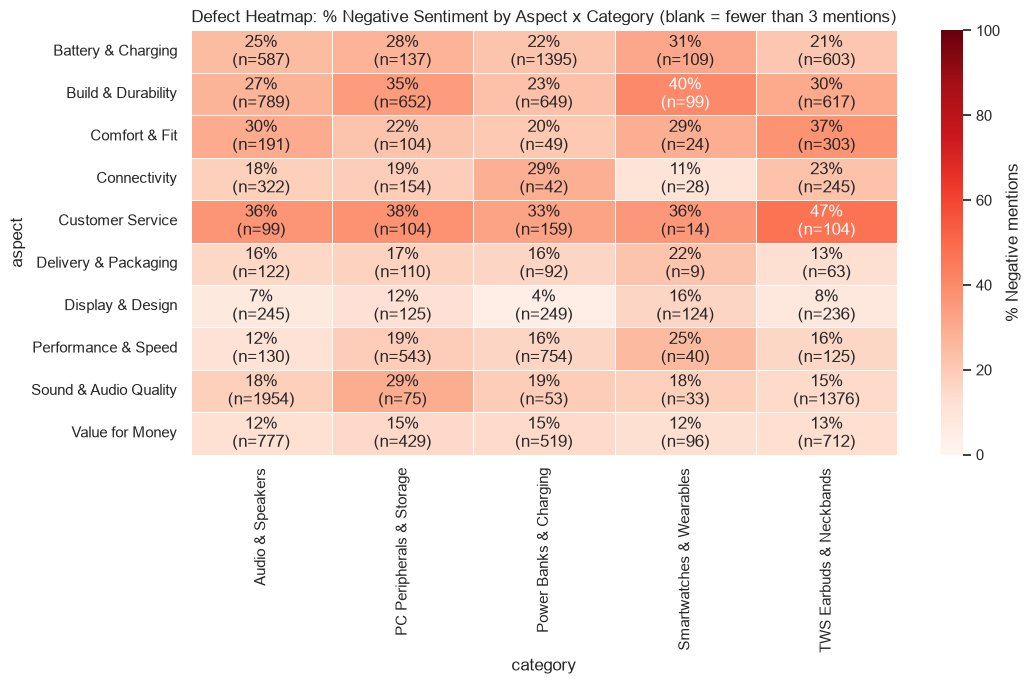

In [15]:
pivot_neg = agg.pivot(index="aspect", columns="category", values="Negative")
pivot_n = agg.pivot(index="aspect", columns="category", values="mentions").fillna(0).astype(int)
mask = pivot_n < 3   # cells with fewer than 3 mentions are too thin to colour
annot = pivot_neg.round(0).fillna(0).astype(int).astype(str) + "%\n(n=" + pivot_n.astype(str) + ")"

plt.figure(figsize=(11, 7))
sns.heatmap(pivot_neg, mask=mask, annot=annot, fmt="", cmap="Reds", vmin=0, vmax=100,
            linewidths=0.5, linecolor="white", cbar_kws={"label": "% Negative mentions"})
plt.title("Defect Heatmap: % Negative Sentiment by Aspect x Category (blank = fewer than 3 mentions)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "04_defect_heatmap.png"), dpi=150)
plt.show()

In [16]:
strong = agg[agg["mentions"] >= 10].sort_values("Negative", ascending=False).head(10)[["category", "aspect", "mentions", "Negative"]]
print("Strongest category x aspect signals (at least 10 mentions), % Negative:")
display(strong)

Strongest category x aspect signals (at least 10 mentions), % Negative:


sentiment,category,aspect,mentions,Negative
44,TWS Earbuds & Neckbands,Customer Service,104,47.1
31,Smartwatches & Wearables,Build & Durability,99,40.4
14,PC Peripherals & Storage,Customer Service,104,37.5
42,TWS Earbuds & Neckbands,Comfort & Fit,303,37.3
4,Audio & Speakers,Customer Service,99,36.4
34,Smartwatches & Wearables,Customer Service,14,35.7
11,PC Peripherals & Storage,Build & Durability,652,34.7
24,Power Banks & Charging,Customer Service,159,32.7
30,Smartwatches & Wearables,Battery & Charging,109,31.2
41,TWS Earbuds & Neckbands,Build & Durability,617,30.5


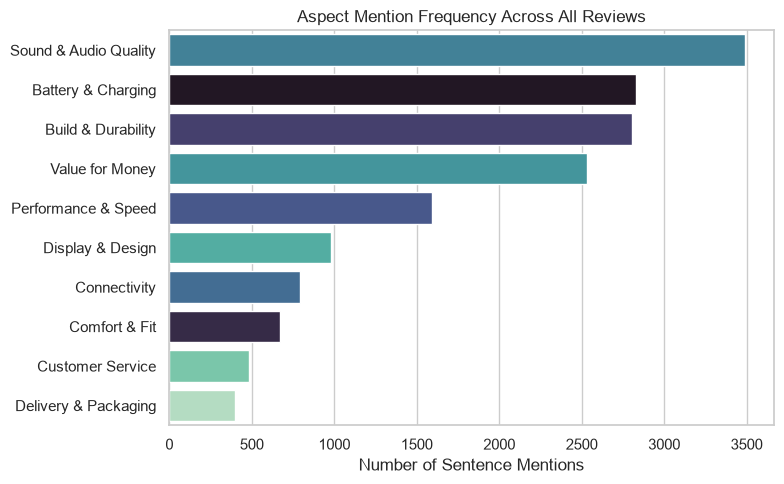

In [17]:
plt.figure(figsize=(8, 5))
order = aspect_df["aspect"].value_counts().index
sns.countplot(data=aspect_df, y="aspect", order=order, hue="aspect", palette="mako", legend=False)
plt.title("Aspect Mention Frequency Across All Reviews")
plt.xlabel("Number of Sentence Mentions"); plt.ylabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "03_aspect_frequency.png"), dpi=150)
plt.show()

**Reading the heatmap.** Percentages are the automatic VADER labels (Section 4b estimates how many "Negative" labels are genuine complaints), so treat every cell as a pointer to read the reviews, not a measured defect rate. Cells with fewer than 3 mentions are blank. The strongest cells with at least 10 mentions are listed in the next cell.

,product_name,avg_rating,reviews,aspect_mentions,pct_negative
8,Baot Wireless Earbuds B5 Neckband 48hrs [176e],2.00,36,37,56.8
18,Boat Bassheads 300c Type C 10mm [5924],2.27,84,94,46.8
40,Mak 80 W Supervooc 6 Wall [768f],3.19,31,31,45.2
28,F Ferons Neo Buds 3 Magnetic [f431],2.60,67,74,39.2
74,Zebronics Glassy 10 Ambidextrous Optical Mouse [3b1b],2.76,87,115,39.1
...,...,...,...,...,...
83,boAt 67W GaN Wall Charger,4.24,93,265,11.7
44,Mivi Fort H350 Soundbar 350 Watts [3844],3.66,134,348,10.9
38,Logitech M240 Wireless Mouse,4.13,54,98,10.2
51,OPPO Enco Air2i,4.06,123,290,9.3


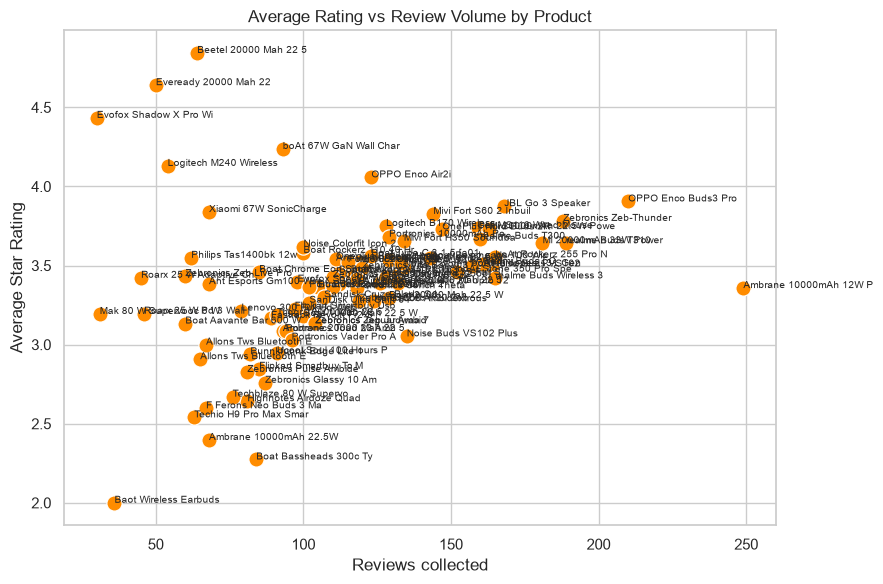

In [18]:
prod_summary = df.groupby("product_name").agg(avg_rating=("rating", "mean"), reviews=("review_id", "count")).reset_index()
prod_neg = (aspect_df.assign(neg=aspect_df["sentiment"] == "Negative")
            .groupby("product_name").agg(aspect_mentions=("neg", "size"), pct_negative=("neg", "mean")))
prod_neg["pct_negative"] = (prod_neg["pct_negative"] * 100).round(1)
prod_table = prod_summary.merge(prod_neg, left_on="product_name", right_index=True).sort_values("pct_negative", ascending=False)
display(prod_table.round(2))

plt.figure(figsize=(9, 6))
sns.scatterplot(data=prod_summary, x="reviews", y="avg_rating", s=120, color="darkorange")
for _, r in prod_summary.iterrows():
    plt.text(r["reviews"] + 0.05, r["avg_rating"], r["product_name"][:22], fontsize=7)
plt.title("Average Rating vs Review Volume by Product")
plt.xlabel("Reviews collected"); plt.ylabel("Average Star Rating")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "07_product_rating_volume.png"), dpi=150)
plt.show()

### 5b. Does the choice of review view change the picture?

The data comes from three views per product (`recent`, `negative_first`, `helpful`). Because the lowest-rated and most-helpful views were taken on purpose, we compare the overall share of negative aspect mentions by view.

In [19]:
aspect_df = aspect_df.merge(df[["review_id", "sample_type"]], on="review_id", how="left")
by_view = aspect_df.groupby("sample_type")["sentiment"].value_counts(normalize=True).unstack(fill_value=0).mul(100).round(1)
by_view["mentions"] = aspect_df.groupby("sample_type").size()
by_view["reviews"] = df.groupby("sample_type").size()
display(by_view)
rec = aspect_df[aspect_df["sample_type"] == "recent"]
print(f"Recent-view only: {(rec['sentiment'] == 'Negative').mean():.1%} of {len(rec):,} mentions are negative "
      f"(all views: {(aspect_df['sentiment'] == 'Negative').mean():.1%} of {len(aspect_df):,})")
rec_aspect = rec.groupby("aspect")["sentiment"].apply(lambda s: (s == "Negative").mean() * 100).round(1)
all_aspect = aspect_df.groupby("aspect")["sentiment"].apply(lambda s: (s == "Negative").mean() * 100).round(1)
display(pd.DataFrame({"pct_negative_all_views": all_aspect, "pct_negative_recent_only": rec_aspect}).sort_values("pct_negative_all_views", ascending=False))

sentiment,Negative,Neutral,Positive,mentions,reviews
sample_type,,,,,
helpful,8.9,16.3,74.8,9317,3972
negative_first,55.1,32.6,12.3,2561,2022
recent,24.3,19.5,56.2,4692,4011


Recent-view only: 24.3% of 4,692 mentions are negative (all views: 20.4% of 16,570)


,pct_negative_all_views,pct_negative_recent_only
aspect,,
Customer Service,37.7,42.8
Comfort & Fit,31.3,38.5
Build & Durability,29.2,31.1
Battery & Charging,23.2,28.9
Connectivity,20.1,27.2
Performance & Speed,17.1,16.0
Sound & Audio Quality,17.0,24.6
Delivery & Packaging,15.9,34.6
Value for Money,13.5,14.1


## 6. Named Entity Recognition  *(Unit III: NER for business intelligence, competitive analysis)*

NER surfaces which **brands, organisations, and named entities** actually show up inside the review text itself — useful for competitive/brand-mention analysis (e.g., "I switched from X to this" or comparisons to other brands), distinct from the `product_name` column we already control.


In [20]:
nlp_ner = spacy.load("en_core_web_sm")  # keep the NER component enabled this time

entity_records = []
for _, row in df.iterrows():
    doc = nlp_ner(str(row["review_text"])[:1000])  # cap length for speed
    for ent in doc.ents:
        if ent.label_ in ("ORG", "PRODUCT", "GPE", "PERSON", "NORP"):
            entity_records.append({"review_id": row["review_id"], "category": row["category"],
                                     "entity": ent.text.strip(), "label": ent.label_})

ent_df = pd.DataFrame(entity_records)
print(f"Extracted {len(ent_df)} named entities ({ent_df['label'].nunique()} entity types)")
display(ent_df["label"].value_counts())
print("\nMost frequently mentioned entities (brands, places, organisations):")
display(ent_df["entity"].value_counts().head(15))

Extracted 3136 named entities (5 entity types)


label
ORG        1618
PERSON     1071
GPE         235
PRODUCT     125
NORP         87
Name: count, dtype: int64


Most frequently mentioned entities (brands, places, organisations):


entity
Bass             252
Flipkart         153
ANC               87
Superb            56
USB               48
Mouse             41
Logitech          36
😔                 32
💰                 27
RGB               25
Power Bank        25
TWS               23
JBL               23
Pros              21
Sound Quality     21
Name: count, dtype: int64

C:\Users\tanoo\AppData\Local\Temp\ipykernel_25424\2446483632.py:7: UserWarning: Glyph 128532 (\N{PENSIVE FACE}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\tanoo\AppData\Local\Temp\ipykernel_25424\2446483632.py:7: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) Arial.
  plt.tight_layout()
C:\Users\tanoo\AppData\Local\Temp\ipykernel_25424\2446483632.py:8: UserWarning: Glyph 128532 (\N{PENSIVE FACE}) missing from font(s) Arial.
  plt.savefig(os.path.join(FIG_DIR, "09_named_entities.png"), dpi=150)
C:\Users\tanoo\AppData\Local\Temp\ipykernel_25424\2446483632.py:8: UserWarning: Glyph 128176 (\N{MONEY BAG}) missing from font(s) Arial.
  plt.savefig(os.path.join(FIG_DIR, "09_named_entities.png"), dpi=150)
C:\Users\tanoo\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128532 (\N{PENSIVE FACE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\tanoo\AppData\Roaming\Python\Python313\site-

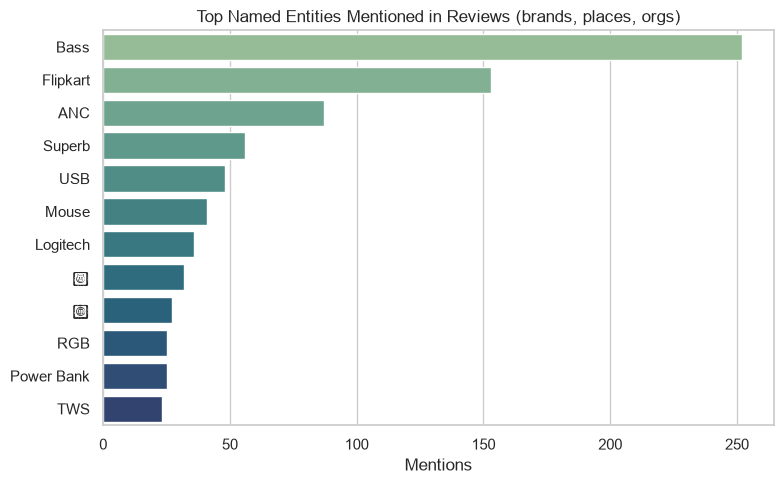

In [21]:
if len(ent_df):
    plt.figure(figsize=(8,5))
    top_ents = ent_df["entity"].value_counts().head(12)
    sns.barplot(x=top_ents.values, y=top_ents.index, hue=top_ents.index, palette="crest", legend=False)
    plt.title("Top Named Entities Mentioned in Reviews (brands, places, orgs)")
    plt.xlabel("Mentions"); plt.ylabel("")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "09_named_entities.png"), dpi=150)
    plt.show()

**Reading this:** off-the-shelf spaCy NER is noisy on short, informal, code-mixed review text. Many "entities" are product jargon or Hindi words mislabelled as ORG/PERSON, so the entity counts above should be inspected by eye before being used. A production version would need a domain-tuned NER model or a curated brand list (see Limitations).

## 7. Document Clustering  *(Unit III: Text classification and document clustering)*

Beyond the pre-defined categories, unsupervised clustering (K-Means on TF-IDF vectors) checks whether reviews naturally group into themes on their own — a cross-check on whether the category labels line up with how customers actually talk about products.


In [22]:
import numpy as np
from sklearn.cluster import KMeans

tfidf_cluster = TfidfVectorizer(max_features=300, stop_words="english", min_df=2)
X_cluster = tfidf_cluster.fit_transform(df["clean_text"])

K = 5
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_cluster)

print("Cluster sizes:")
display(df["cluster"].value_counts().sort_index())

print("\nCluster vs. actual category (do clusters line up with categories?):")
display(pd.crosstab(df["cluster"], df["category"]))

print("\nTop terms per cluster:")
terms = np.array(tfidf_cluster.get_feature_names_out())
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1]
for i in range(K):
    top_terms = terms[order_centroids[i, :8]]
    print(f"Cluster {i}: {', '.join(top_terms)}")

Cluster sizes:


cluster
0     565
1     687
2    5492
3    1477
4    1784
Name: count, dtype: int64


Cluster vs. actual category (do clusters line up with categories?):


category,Audio & Speakers,PC Peripherals & Storage,Power Banks & Charging,Smartwatches & Wearables,TWS Earbuds & Neckbands
cluster,,,,,
0,143,105,104,48,165
1,150,161,143,85,148
2,1150,1338,1688,329,987
3,386,318,364,72,337
4,933,100,86,19,646



Top terms per cluster:
Cluster 0: bad, product, quality, working, don, battery, buy, money
Cluster 1: nice, product, good, quality, sound, money, value, price
Cluster 2: product, working, charging, best, money, buy, battery, good
Cluster 3: good, product, quality, price, sound, money, battery, backup
Cluster 4: quality, sound, bass, good, best, poor, battery, product


**Interpretation:** compare the cluster-by-category table above: clusters that mix categories are grouping reviews by what they say (for example "good product, value for money" or "stopped working") rather than by product type, which is expected for short review text. At production scale this view helps find emerging themes the fixed aspect list does not capture.

## 8. Trend Detection Over Time  *(Unit III: Trend detection and competitive analysis from text)*

Flipkart shows recent reviews as "N days ago" and older ones as "Month, Year", so dates are approximate (month resolution for older reviews). Because most reviews come from the recent and most-helpful views, the monthly chart shows **mechanism, not a statistically meaningful trend**.

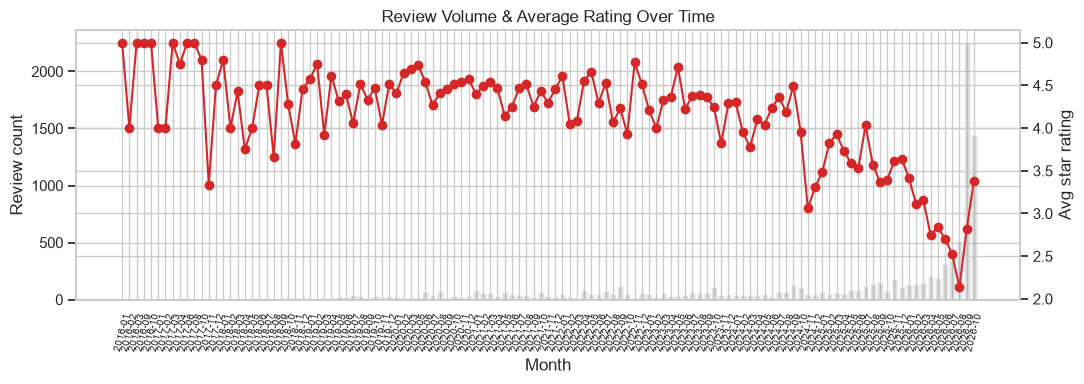

In [23]:
trend = df.dropna(subset=["review_date_parsed"]).copy()
trend["month"] = trend["review_date_parsed"].dt.to_period("M").astype(str)
monthly = trend.groupby("month").agg(avg_rating=("rating","mean"), avg_vader=("vader_compound","mean"), n=("review_id","count")).reset_index()
monthly = monthly[monthly["n"] >= 1].sort_values("month")

fig, ax1 = plt.subplots(figsize=(11,4))
ax1.bar(monthly["month"], monthly["n"], alpha=0.25, color="gray", label="Review count")
ax1.set_ylabel("Review count"); ax1.set_xlabel("Month")
plt.xticks(rotation=75, fontsize=7)
ax2 = ax1.twinx()
ax2.plot(monthly["month"], monthly["avg_rating"], color="#d62728", marker="o", label="Avg star rating")
ax2.set_ylabel("Avg star rating")
plt.title("Review Volume & Average Rating Over Time")
fig.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "10_trend_over_time.png"), dpi=150)
plt.show()

**Caveat:** review volume per month is uneven and dates are approximate, so the average-rating line is indicative only. The mechanism is what a live monitoring dashboard would run continuously as new reviews arrive.

## 9. Extractive Text Summarisation  *(Unit III: Text summarization for managerial reports)*

Rather than a manager reading all 1-2 star reviews individually, an extractive summary — the single highest-signal sentence per category — gives a fast "what's actually wrong" readout.


In [24]:
def extractive_summary(text_series, top_n=1):
    sentences = []
    for t in text_series:
        sentences.extend(sent_tokenize(str(t)))
    if not sentences:
        return []
    vec = TfidfVectorizer(stop_words="english")
    try:
        X_sent = vec.fit_transform(sentences)
    except ValueError:
        return sentences[:top_n]
    centroid = np.asarray(X_sent.mean(axis=0))
    scores = np.asarray(X_sent @ centroid.T).ravel()
    top_idx = scores.argsort()[::-1][:top_n]
    return [sentences[i] for i in top_idx]

print("One-sentence defect summary per category (from 1-3 star reviews):\n")
for cat in sorted(df["category"].unique()):
    neg_text = df[(df["category"] == cat) & (df["rating"] <= 3)]["review_text"]
    if len(neg_text) == 0:
        continue
    summary = extractive_summary(neg_text, top_n=1)
    print(f"-- {cat} --")
    for s in summary:
        print(f"   \"{s.strip()}\"")
    print()

One-sentence defect summary per category (from 1-3 star reviews):

-- Audio & Speakers --
   "Not a good product sound quality is not good"

-- PC Peripherals & Storage --
   "Product is not working and very bad quality."

-- Power Banks & Charging --
   "Very bad, fast charging is not working.... Don't buy this product.🤯🤯🤬🤬🤬"

-- Smartwatches & Wearables --
   "Bad product watch"

-- TWS Earbuds & Neckbands --
   "very bad product.sound is not good.very bad quality."



## 10. Word Embeddings  *(Unit IV: Word embeddings — Word2Vec, GloVe, FastText; contextual embeddings & BERT — conceptual)*

A small **Word2Vec** model trained directly on this review corpus (via Gensim — works fully offline, no internet needed, unlike a pretrained transformer) shows which words the model learns associate with key aspect terms, purely from co-occurrence in these reviews.


In [25]:
from gensim.models import Word2Vec

sentences_for_w2v = df["lemmas"].tolist()
w2v = Word2Vec(sentences=sentences_for_w2v, vector_size=50, window=5, min_count=2, workers=1, epochs=100, seed=42)

print(f"Vocabulary size: {len(w2v.wv.key_to_index)} words (small corpus -> small vocab, see Limitations)\n")
for term in ["battery", "sound", "quality", "price", "service"]:
    if term in w2v.wv.key_to_index:
        print(f"Most similar to '{term}':", w2v.wv.most_similar(term, topn=5))
    else:
        print(f"'{term}' not in vocabulary (min_count=2 filter)")

Vocabulary size: 2517 words (small corpus -> small vocab, see Limitations)

Most similar to 'battery': [('hrs', 0.6077940464019775), ('bettery', 0.5670405030250549), ('continuously', 0.5114865303039551), ('upto', 0.5084221363067627), ('hour', 0.5051448941230774)]
Most similar to 'sound': [('bass', 0.8677107691764832), ('vocal', 0.6436457633972168), ('loudness', 0.6290797591209412), ('separation', 0.617024302482605), ('audio', 0.5990024209022522)]
Most similar to 'quality': [('bass', 0.5851096510887146), ('clarity', 0.5749654769897461), ('decent', 0.5648984313011169), ('sound', 0.5570430755615234), ('good', 0.5489374399185181)]
Most similar to 'price': [('great', 0.5158904194831848), ('budget', 0.49772584438323975), ('fair', 0.49189919233322144), ('cost', 0.4896388351917267), ('good', 0.4865078926086426)]
Most similar to 'service': [('seller', 0.6225492358207703), ('process', 0.5952209234237671), ('lith', 0.5811899900436401), ('replacement', 0.5652848482131958), ('visit', 0.550800383090

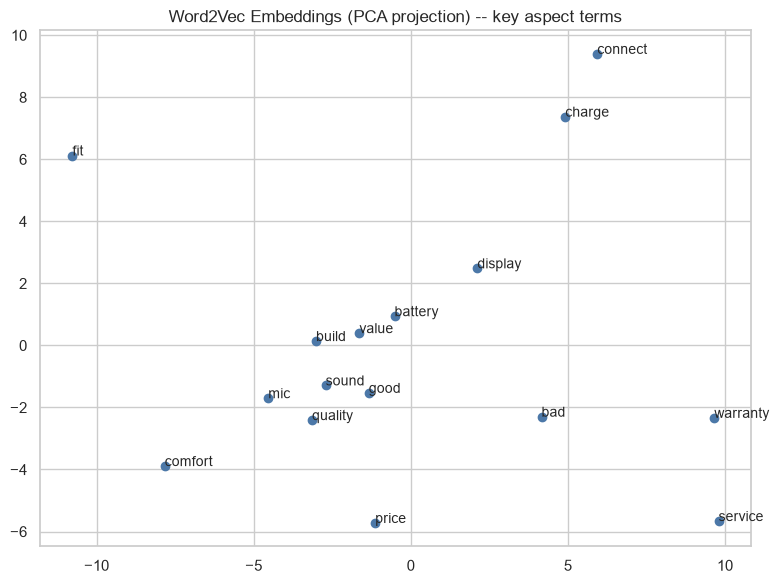

In [26]:
from sklearn.decomposition import PCA

vocab_terms = [w for w in ["battery","sound","quality","price","service","connect",
                             "comfort","display","build","value","good","bad","warranty",
                             "charge","mic","fit"] if w in w2v.wv.key_to_index]
if len(vocab_terms) >= 3:
    vecs = np.array([w2v.wv[w] for w in vocab_terms])
    coords = PCA(n_components=2, random_state=42).fit_transform(vecs)
    plt.figure(figsize=(8,6))
    plt.scatter(coords[:,0], coords[:,1], color="#4C78A8")
    for i, w in enumerate(vocab_terms):
        plt.annotate(w, (coords[i,0], coords[i,1]), fontsize=10)
    plt.title("Word2Vec Embeddings (PCA projection) -- key aspect terms")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, "11_word2vec_pca.png"), dpi=150)
    plt.show()
else:
    print("Not enough vocabulary overlap to plot -- expected with this corpus size.")

**On BERT / contextual embeddings (conceptual, per Unit IV):** a transformer like BERT would improve on this static Word2Vec model by giving each word a *context-dependent* vector (so "charge" in "charge the battery" vs. "additional charge" gets different representations) — which static embeddings and the lexicon-based ABSA in Section 4 cannot do. This project could not download BERT weights (no HuggingFace Hub access in this sandbox), but the architecture tradeoff is noted here: **lexicon/VADER → fast, transparent, no training data needed, but context-blind; Word2Vec → learns from the corpus, still context-blind; BERT/transformer ABSA → context-aware, state-of-the-art accuracy, but needs significant compute and (for a fine-tuned checkpoint) internet access or local weights.**

## 11. Topic Modelling — Emerging Defect Themes (Gensim LDA)  *(Unit III: Topic modeling (LDA) for business themes)*

Unsupervised topic modelling on the **negative/critical reviews** (1-2 star) surfaces recurring complaint themes the lexicon might not fully capture, in the reviewers' own words.


In [27]:
from gensim import corpora
from gensim.models import LdaModel

neg_docs = df[df["rating"] <= 2]["lemmas"].tolist()
if len(neg_docs) < 3:
    neg_docs = df[df["rating"] <= 3]["lemmas"].tolist()

dictionary = corpora.Dictionary(neg_docs)
dictionary.filter_extremes(no_below=2, no_above=0.8)
corpus = [dictionary.doc2bow(doc) for doc in neg_docs]
print(f"LDA is trained on {len(neg_docs)} documents (reviews rated 2 stars or below; falls back to 3 stars or below only if fewer than 3)")

NUM_TOPICS = 4
lda = LdaModel(corpus=corpus, id2word=dictionary, num_topics=NUM_TOPICS, random_state=42, passes=20, alpha="auto")

for idx, topic in lda.print_topics(num_words=8):
    print(f"Topic {idx}: {topic}\n")

LDA is trained on 3319 documents (reviews rated 2 stars or below; falls back to 3 stars or below only if fewer than 3)
Topic 0: 0.113*"bad" + 0.104*"product" + 0.083*"quality" + 0.047*"good" + 0.045*"buy" + 0.040*"sound" + 0.039*"money" + 0.033*"waste"

Topic 1: 0.023*"mouse" + 0.022*"use" + 0.017*"time" + 0.015*"issue" + 0.014*"problem" + 0.011*"connect" + 0.011*"get" + 0.011*"even"

Topic 2: 0.196*"work" + 0.086*"month" + 0.062*"day" + 0.049*"stop" + 0.037*"use" + 0.036*"one" + 0.032*"properly" + 0.027*"within"

Topic 3: 0.105*"charge" + 0.045*"battery" + 0.040*"power" + 0.031*"bank" + 0.031*"phone" + 0.021*"slow" + 0.020*"fast" + 0.020*"charging"



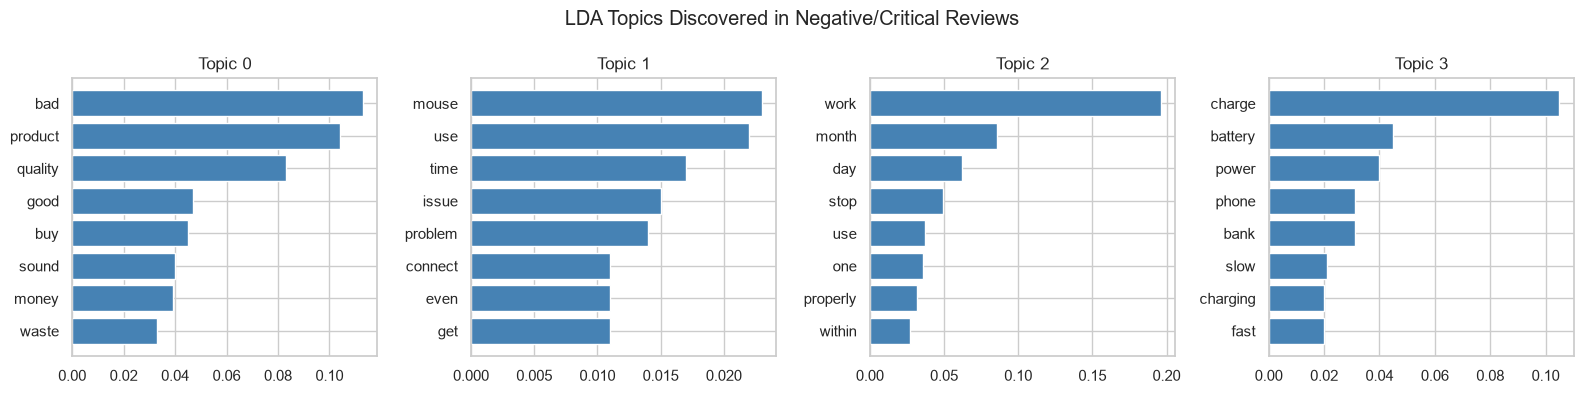

In [28]:
topic_rows = [{"topic": t, "word": w, "weight": round(float(wt), 3)}
              for t in range(NUM_TOPICS) for w, wt in lda.show_topic(t, topn=8)]
lda_topics = pd.DataFrame(topic_rows)
lda_topics.to_csv(os.path.join(OUT_DIR, "lda_topics.csv"), index=False)

fig, axes = plt.subplots(1, NUM_TOPICS, figsize=(4 * NUM_TOPICS, 4))
for i, t in enumerate(sorted(lda_topics["topic"].unique())):
    sub = lda_topics[lda_topics["topic"] == t].sort_values("weight")
    axes[i].barh(sub["word"], sub["weight"], color="steelblue")
    axes[i].set_title(f"Topic {t}")
plt.suptitle("LDA Topics Discovered in Negative/Critical Reviews")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "06_lda_topics.png"), dpi=150)
plt.show()

**Interpretation:** the topics are built from the 1-2 star reviews only (the document count is printed above). Read them as themes to investigate, not as proof; several topics may mix aspects because many negative reviews are short.

## 12. Supervised Benchmark: TF-IDF + ML Classifier  *(Unit III: Sentiment analysis — ML-based; Text classification)*

As the **ML-based** counterpart to the rule-based VADER sentiment in Section 4 (the exact "rule-based vs. ML-based" comparison the course asks for), a supervised classifier is trained directly on **star rating as ground truth** using TF-IDF features.


In [29]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import classification_report, accuracy_score, f1_score, recall_score, confusion_matrix

df_sup = df[df["rating"].isin([1,2,4,5])].copy()
df_sup["label"] = df_sup["rating"].apply(lambda r: "Positive" if r >= 4 else "Negative")
X_text = df_sup["clean_text"]
y = df_sup["label"]

# Keep negation words ("not", "no", "never"...) - sklearn's default stop list would delete them
NEGATIONS = {"not", "no", "nor", "never", "nothing", "cannot", "without", "none"}
STOP = sorted(set(ENGLISH_STOP_WORDS) - NEGATIONS)

def make_pipeline(model):
    # The vectoriser sits INSIDE the pipeline, so it is fitted on training data only (no leakage)
    return Pipeline([("tfidf", TfidfVectorizer(max_features=500, ngram_range=(1,2), stop_words=STOP, min_df=1)),
                     ("clf", model)])

models = [("Logistic Regression", LogisticRegression(max_iter=1000, class_weight="balanced")),
          ("Multinomial Naive Bayes", MultinomialNB())]

X_train, X_test, y_train, y_test = train_test_split(X_text, y, test_size=0.25, random_state=42, stratify=y)
baseline = (y_test == "Positive").mean()
print(f"Training reviews: {len(X_train)} | Test reviews: {len(X_test)} ({(y_test == 'Negative').sum()} negative)")
print(f"Majority-class baseline accuracy on the test set: {baseline:.2f}\n")

results = []
for name, model in models:
    pipe = make_pipeline(model).fit(X_train, y_train)
    preds = pipe.predict(X_test)
    print(f"=== {name} (single 75/25 split) ===")
    print(classification_report(y_test, preds, zero_division=0))
    print(confusion_matrix(y_test, preds, labels=["Negative", "Positive"]), " <- rows: true Negative/Positive, columns: predicted\n")
    # With only 9 negative reviews, one split is very unstable, so also use 3-fold stratified cross-validation
    cv_preds = cross_val_predict(make_pipeline(model), X_text, y, cv=StratifiedKFold(3, shuffle=True, random_state=42))
    print(f"3-fold CV: accuracy {accuracy_score(y, cv_preds):.2f}, negative recall {recall_score(y, cv_preds, pos_label='Negative'):.2f}, "
          f"negative precision {(cv_preds[(cv_preds == 'Negative')] == y[(cv_preds == 'Negative')]).mean() if (cv_preds == 'Negative').any() else 0:.2f}, "
          f"macro-F1 {f1_score(y, cv_preds, average='macro'):.2f}\n")
    results.append({"model": name, "accuracy": round(accuracy_score(y_test, preds), 3),
                    "f1_positive": round(f1_score(y_test, preds, pos_label="Positive"), 3),
                    "negative_recall": round(recall_score(y_test, preds, pos_label="Negative"), 3),
                    "macro_f1": round(f1_score(y_test, preds, average="macro"), 3),
                    "majority_baseline": round(baseline, 3), "test_size": len(y_test),
                    "cv_accuracy": round(accuracy_score(y, cv_preds), 3),
                    "cv_negative_recall": round(recall_score(y, cv_preds, pos_label="Negative"), 3),
                    "cv_macro_f1": round(f1_score(y, cv_preds, average="macro"), 3)})

pd.DataFrame(results).to_csv(os.path.join(OUT_DIR, "classifier_results.csv"), index=False)
pd.DataFrame(results)

Training reviews: 7067 | Test reviews: 2356 (830 negative)
Majority-class baseline accuracy on the test set: 0.65

=== Logistic Regression (single 75/25 split) ===
              precision    recall  f1-score   support

    Negative       0.90      0.94      0.92       830
    Positive       0.96      0.94      0.95      1526

    accuracy                           0.94      2356
   macro avg       0.93      0.94      0.94      2356
weighted avg       0.94      0.94      0.94      2356

[[ 777   53]
 [  85 1441]]  <- rows: true Negative/Positive, columns: predicted

3-fold CV: accuracy 0.94, negative recall 0.93, negative precision 0.89, macro-F1 0.93

=== Multinomial Naive Bayes (single 75/25 split) ===
              precision    recall  f1-score   support

    Negative       0.94      0.82      0.87       830
    Positive       0.91      0.97      0.94      1526

    accuracy                           0.92      2356
   macro avg       0.92      0.89      0.91      2356
weighted avg   

,model,accuracy,f1_positive,negative_recall,macro_f1,majority_baseline,test_size,cv_accuracy,cv_negative_recall,cv_macro_f1
0,Logistic Regression,0.941,0.954,0.936,0.936,0.648,2356,0.936,0.933,0.931
1,Multinomial Naive Bayes,0.917,0.938,0.816,0.906,0.648,2356,0.913,0.810,0.901


In [30]:
# Which TF-IDF terms are associated with Positive vs Negative? (descriptive only: a final model fitted on all labelled reviews;
# these are associations inside the classifier, not causes of dissatisfaction)
final_pipe = make_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced")).fit(X_text, y)
tfidf = final_pipe.named_steps["tfidf"]
feat_names = np.array(tfidf.get_feature_names_out())
coefs = final_pipe.named_steps["clf"].coef_[0]
top_pos = feat_names[np.argsort(coefs)[-15:]][::-1]
top_neg = feat_names[np.argsort(coefs)[:15]]
top_terms_df = pd.DataFrame({"positive_terms": top_pos, "negative_terms": top_neg})
top_terms_df.to_csv(os.path.join(OUT_DIR, "top_tfidf_terms.csv"), index=False)
top_terms_df

,positive_terms,negative_terms
0,good,not
1,best,poor
2,awesome,worst
3,nice,bad
4,amazing,don buy
5,excellent,not good
6,great,waste
7,super,don
8,superb,month
9,love,low


**Reading the classifier result.** TF-IDF is fitted inside a scikit-learn Pipeline, so it only sees training data, and negation words ("not", "no", "never") are kept. Compare each model's accuracy with the majority-class baseline printed above, and read **negative recall and macro-F1** (cross-validated numbers are more stable than the single split). The coefficients describe associations inside the classifier, not causes of dissatisfaction.

### 12b. Train on the whole Amazon `Electronics_5.json` file, test on Flipkart

`Electronics_5.json` is the public Amazon Electronics review file (about 1.7 million reviews, collected years ago from Amazon's US store). Flipkart is our **main data**, so here it plays the role of the **test set**, and the old Amazon file is used only as **training data**. The question: if a seller only had this old, large Amazon file, would a model trained on it still recognise negative reviews on Flipkart? None of the business findings come from Amazon.

This version uses the **whole file, not a random sample**. It is read line by line, cleaned the same way as our own data (at least 3 words, duplicates removed, only 1-2 and 4-5 star reviews), and used to train Logistic Regression and Naive Bayes (TF-IDF, 500 terms). The trained models are then tested on all of the Flipkart reviews they have never seen. The result is compared with the Flipkart-only models of section 12a.

Put `Electronics_5.json` in the `data/` folder (it is ignored by git because it is 1.48 GB). If the file is missing, the cell falls back to the 18,376-review sample in `data/amazon_electronics5_test_sample.csv`.

In [31]:
import json, collections
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

AMZ_CANDIDATES = [os.path.join(BASE, "data", "Electronics_5.json"),
                  os.path.join(os.path.dirname(BASE), "_old_to_delete", "archive (3)", "Electronics_5.json")]
AMZ_JSON = next((p for p in AMZ_CANDIDATES if os.path.exists(p)), None)

def load_amazon_full(path):
    ratings, texts, seen, total = [], [], set(), 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            total += 1
            d = json.loads(line)
            t = (d.get("reviewText") or "").strip()
            r = int(d.get("overall", 0))
            if not t or r not in (1, 2, 4, 5):
                continue
            if len(re.findall(r"[A-Za-z]+", t)) < 3:
                continue
            key = hash(re.sub(r"[^a-z0-9 ]", "", t.lower()).strip())
            if key in seen:
                continue
            seen.add(key); ratings.append(r); texts.append(t)
    print(f"Read {total:,} lines from {os.path.basename(path)}; kept {len(texts):,} reviews after cleaning")
    return pd.DataFrame({"rating": ratings, "review_text": texts})

if AMZ_JSON:
    amz = load_amazon_full(AMZ_JSON)
    amz_source = "whole file"
else:
    print("Electronics_5.json not found, using the 18,376-review sample instead")
    amz = pd.read_csv(os.path.join(BASE, "data", "amazon_electronics5_test_sample.csv")).dropna(subset=["review_text"])
    amz["n_words"] = amz["review_text"].str.findall(r"[A-Za-z]+").str.len()
    amz = amz[(amz["n_words"] >= 3) & amz["rating"].isin([1, 2, 4, 5])].copy()
    amz["norm"] = amz["review_text"].str.lower().str.replace(r"[^a-z0-9 ]", "", regex=True).str.strip()
    amz = amz.drop_duplicates("norm")[["rating", "review_text"]].reset_index(drop=True)
    amz_source = "18,376-review sample"
amz["clean_text"] = amz["review_text"].apply(clean_text)
amz["label"] = np.where(amz["rating"] >= 4, "Positive", "Negative")
print(f"Amazon Electronics_5 training data ({amz_source}): {len(amz):,} reviews ({(amz['label'] == 'Negative').sum():,} negative, "
      f"{(amz['label'] == 'Negative').mean():.0%}). Flipkart test data: {len(y):,} reviews ({(y == 'Negative').mean():.0%} negative; "
      f"majority baseline {(y == 'Positive').mean():.2f})")

# TF-IDF vocabulary of the 500 most frequent terms, counted chunk by chunk (same rule as TfidfVectorizer(max_features=500)),
# so the full vocabulary of 1.4 million reviews never has to sit in memory.
counts = collections.Counter()
for i in range(0, len(amz), 100_000):
    cv = CountVectorizer(ngram_range=(1, 2), stop_words=STOP)
    Xc = cv.fit_transform(amz["clean_text"].iloc[i:i + 100_000])
    counts.update(dict(zip(cv.get_feature_names_out(), np.asarray(Xc.sum(axis=0)).ravel())))
amz_vocab = [w for w, _ in counts.most_common(500)]
amz_vec = TfidfVectorizer(ngram_range=(1, 2), stop_words=STOP, vocabulary=amz_vocab)
X_amz = amz_vec.fit_transform(amz["clean_text"])
X_fk = amz_vec.transform(X_text)

ood = []
for name, model in models:
    m2 = type(model)(**model.get_params()).fit(X_amz, amz["label"])
    pred = m2.predict(X_fk)
    rec = recall_score(y, pred, pos_label="Negative")
    prec = (y[pred == "Negative"] == "Negative").mean() if (pred == "Negative").any() else 0.0
    ood.append({"setting": f"train Amazon ({amz_source}) -> test Flipkart", "model": name,
                "accuracy": round(accuracy_score(y, pred), 3), "negative_recall": round(rec, 3),
                "negative_precision": round(prec, 3), "macro_f1": round(f1_score(y, pred, average="macro"), 3),
                "test_reviews": len(y)})
ood_df = pd.DataFrame(ood)
ood_df.to_csv(os.path.join(OUT_DIR, "out_of_domain_results.csv"), index=False)
ood_df

Read 1,689,188 lines from Electronics_5.json; kept 1,543,743 reviews after cleaning
Amazon Electronics_5 training data (whole file): 1,543,743 reviews (190,607 negative, 12%). Flipkart test data: 9,423 reviews (35% negative; majority baseline 0.65)


,setting,model,accuracy,negative_recall,negative_precision,macro_f1,test_reviews
0,train Amazon (whole file) -> test Flipkart,Logistic Regression,0.850,0.917,0.727,0.843,9423
1,train Amazon (whole file) -> test Flipkart,Multinomial Naive Bayes,0.652,0.012,1.000,0.406,9423


**Reading the Amazon-trained result.** The majority-class baseline for Flipkart is 0.65; a model is only useful if its **negative recall and macro-F1** are good as well. Comparing these scores with the Flipkart-only models of Section 12 shows how much of what a classifier needs is specific to the marketplace it will be used on. Amazon is used only as outside training data, which is why no business conclusion comes from it.

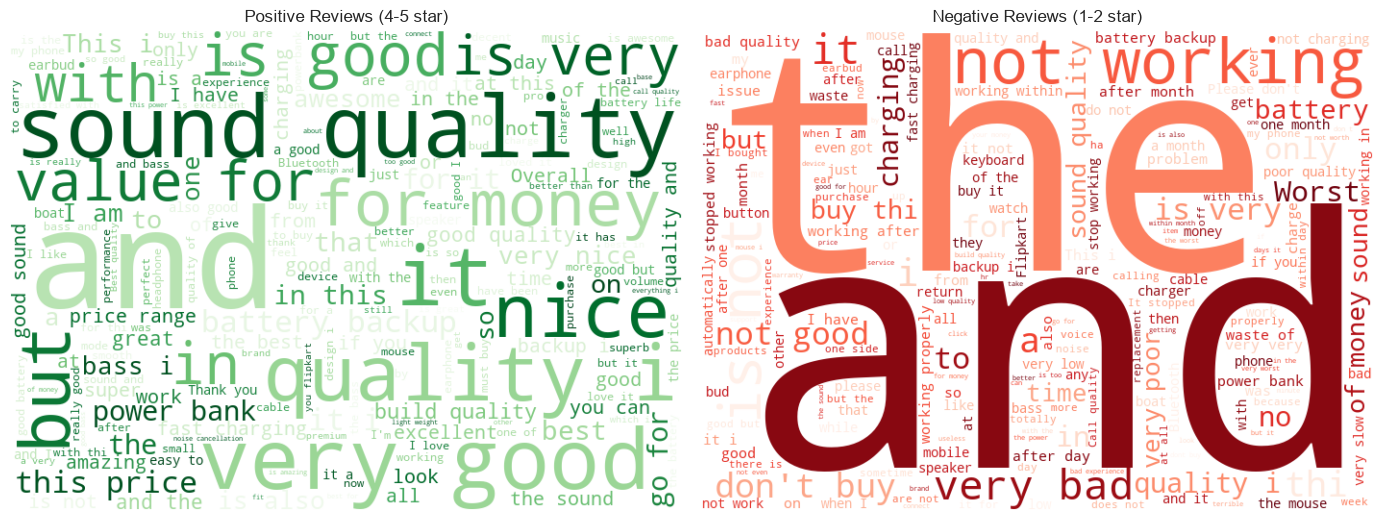

In [32]:
from wordcloud import WordCloud

pos_text = " ".join(df[df["rating"] >= 4]["clean_text"].astype(str))
neg_text = " ".join(df[df["rating"] <= 2]["clean_text"].astype(str))
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, text, title, cmap in [(axes[0], pos_text, "Positive Reviews (4-5 star)", "Greens"),
                               (axes[1], neg_text, "Negative Reviews (1-2 star)", "Reds")]:
    wc = WordCloud(width=700, height=500, background_color="white", colormap=cmap,
                   stopwords={"product", "amazon", "india", "use", "using", "used"}).generate(text or "no data")
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(title)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "05_wordclouds.png"), dpi=150)
plt.show()

### Interactive dashboard  *(Unit IV: NLP + BI dashboard integration)*

The same results as a single interactive Plotly page (`outputs/dashboard.html`) that a manager can open in a browser, hover and filter without running any code.


In [33]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

dash = make_subplots(
    rows=2, cols=2, horizontal_spacing=0.28, vertical_spacing=0.30,
    subplot_titles=("Star Rating Distribution", "Aspect Mention Frequency",
                    "% Negative by Aspect & Category (blank = under 3 mentions)", "15 Lowest-Rated Products (avg stars)"),
    specs=[[{"type": "bar"}, {"type": "bar"}], [{"type": "heatmap"}, {"type": "bar"}]])

rc = df["rating"].value_counts().sort_index()
dash.add_trace(go.Bar(x=rc.index.astype(str), y=rc.values, marker_color="#4C78A8"), row=1, col=1)
ac = aspect_df["aspect"].value_counts().sort_values()
dash.add_trace(go.Bar(x=ac.values, y=ac.index, orientation="h", marker_color="#72B7B2"), row=1, col=2)
dash.add_trace(go.Heatmap(z=pivot_neg.where(~mask).values, x=pivot_neg.columns, y=pivot_neg.index, colorscale="Reds",
                          zmin=0, zmax=100, colorbar=dict(title="% Neg", x=0.40, y=0.17, len=0.3, thickness=12)), row=2, col=1)
ps = prod_summary.sort_values("avg_rating").head(15).copy()
ps["short"] = ps["product_name"].str.slice(0, 32)
dash.add_trace(go.Bar(x=ps["avg_rating"], y=ps["short"], orientation="h", marker_color="#F58518",
                      customdata=ps["product_name"], hovertemplate="%{customdata}<br>%{x:.2f} stars<extra></extra>"), row=2, col=2)
dash.update_xaxes(range=[0, 5], row=2, col=2)
dash.update_yaxes(autorange="reversed", row=2, col=2)
dash.update_layout(height=1000, width=1500, showlegend=False, margin=dict(l=160, r=60, t=100, b=140),
                   title_text="E-Commerce Sentiment Analysis & Defect Diagnostics - Executive Dashboard")
dash.write_html(os.path.join(OUT_DIR, "dashboard.html"))
print("Saved interactive dashboard to", os.path.join(OUT_DIR, "dashboard.html"))

Saved interactive dashboard to c:\Users\tanoo\OneDrive\Documents\MBA\NLP\Project\Flipkart_Capstone\outputs_flipkart\dashboard.html


## 13. Key Insights (Flipkart dataset: 10,005 reviews, 91 products, 5 categories)

1. **Where the defects are.** Of 16,570 aspect mentions, 20.4% are negative. The highest negative shares are **Customer Service (37.7%)**, **Comfort & Fit (31.3%)** and **Build & Durability (29.2%)**, then Battery & Charging (23.2%). Display & Design (8.6%) and Value for Money (13.5%) are the safest.
2. **Category hot-spots (at least 10 mentions).** TWS earbuds: Customer Service 47.1% and Comfort & Fit 37.3% negative. Smartwatches: Build & Durability 40.4%. PC peripherals: Build & Durability 34.7% (652 mentions, the largest hot-spot) and Customer Service 37.5%.
3. **Sampling changes the picture.** The negative share is 8.9% in the "most helpful" view, 24.3% in the "most recent" view and 55.1% in the "negative first" view. The headline 20.4% depends on this mix, so compare aspects with each other rather than quoting it as a market-wide rate. Using only the recent view, the order of the top aspects stays the same (Customer Service 42.8%, Comfort & Fit 38.5%, Build 31.1%).
4. **Auditing the tags.** In a random sample of 80 VADER-Negative mentions, 53 (66%, 95% interval 55%-76%) were genuine complaints about the tagged aspect. The rest were praise misread or complaints about a different aspect. Negative shares are therefore upper-bound signals, not exact defect rates.
5. **Predicting sentiment.** VADER agrees with star-based sentiment on 77.6% of reviews (always-Positive baseline 61.0%). Logistic regression reaches 0.94 accuracy and 0.93 negative recall on the held-out 25% (3-fold CV 0.94 / 0.93), above Naive Bayes (0.92 / 0.82).
6. **Trained on the old Amazon file, tested on Flipkart (1,543,743 cleaned Electronics_5 reviews).** The Amazon-trained logistic regression scored 0.85 accuracy on Flipkart (negative recall 0.92, precision 0.73), behind the Flipkart-only model (0.94). Naive Bayes trained on Amazon predicts almost everything as Positive (negative recall 0.01) because 88% of Amazon reviews are positive. Models transfer only partly.
7. **Product spread.** Average ratings range from 2.0 to 4.8 across the 91 products, so product-level comparison is possible; the lowest averages are a neckband (2.0), a Type-C earphone (2.3) and a 10000mAh power bank (2.4).


## 14. Limitations

- **Non-random sample.** Reviews come from three views (recent, negative-first, most-helpful) of 91 public product pages found by searching Flipkart categories. Percentages describe this sample, not all buyers.
- **Product variants.** Some listings are colour or pack variants of the same model. Cross-listing copy-paste was removed (2,165 reviews), but a few products are close relatives. Product names for newly added products are shortened from the web address.
- **Approximate dates.** Flipkart shows relative dates ("7 days ago", "Mon, 2024"), so trend charts are approximate.
- **Small groups.** Smartwatches have 553 reviews and some category-aspect cells are small (e.g. Smartwatch Customer Service, 14 mentions); read those with their confidence intervals.
- **Rule-based tagging.** The aspect lexicon and VADER misread sarcasm, mixed sentences and mentions of other products. The 80-mention audit puts Negative-tag precision at about 66% (53 of 80). That audit was a first pass by the assistant and should be re-checked by the team.
- **Strict cleaning removes real reviews.** Short, garbage, duplicate and copy-paste reviews were dropped (23,046 raw to 10,005), which favours longer reviews (median 9 words).
- **Old training file.** Electronics_5.json is a roughly six-year-old Amazon file with different products and a very positive mix (88%); it is used only as outside training data, never for a business finding.
- **Only Flipkart.** Amazon.in needed a login, which we did not bypass.

## 15. Conclusion
The pipeline cleans and tags ten thousand real reviews across 91 products and points to Customer Service, Comfort & Fit and Build & Durability as the main complaint areas. The results show where to look; they are not exact defect rates.
